## Module 3: Computational Drug Discovery Project
Claire Meehan <br>
Anna Brady

## Project Goal:

You are working as a Quantitative Systems Pharmacologist at the UVA Manning Institute for Biotechnology. Your overall goal is to help develop a GLP1 agonist drug for weight loss, branded Cavalitide, that will compete with semaglutide (Ozempic or Wegovy). Your project is composed of three tasks:
* Task 1: Fit a receptor binding (pharmacodynamics) model for Cavalitide
* Task 2: Simulate the pharmacokinetics of Cavalitide treatment
* Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment.
  
The below sections should be addressed in your Project Report as a Jupyter notebook, based on Module3_Project_Template.ipynb. All groups submit a Project Report, only those in the Sullivan Company have Oral Presentations (**all due 11/17**).

## Disease Background: 

Obesity is a disease involving having an excessive amount of body fat. It is typically diagnosed using BMI, or body mass index. BMI is calculated by multiplying weight in pounds by 703, then dividing by height in inches twice. Obesity is typically defined by a BMI of 30 or higher. Obesity can be caused by family, lifestyle choices, diseases/medicines, social/economic issues, age, and other factors. It can cause heart disease, diabetes, cancer, and other diseases [1](https://www.mayoclinic.org/diseases-conditions/obesity/symptoms-causes/syc-20375742). Current treatments include GLP-1 agonists/semaglutide injections such as Ozempic or Wegovy. GLP-1 is a hormone that triggers insulin release, blocks glucagon secretion (preventing glucose from entering the bloodstream), increases the full feeling after eating, and slows stomach emptying. GLP-1 agonists work through mimicking GLP-1, decreasing blood sugar spikes and helping to promote weight loss [2](https://my.clevelandclinic.org/health/treatments/13901-glp-1-agonists). However, current semaglutide therapies can cause unwanted side effects such as nausea, vomiting, constipation, diarrhea, and serious digestive issues [3](https://consultqd.clevelandclinic.org/a-new-tool-in-the-obesity-management-toolbox). They can also be costly, and their injectable nature makes patients less inclined to persistently use them [4](https://pmc.ncbi.nlm.nih.gov/articles/PMC13675972/#s0006). Therefore, there is still room in the market for new treatments to obesity.


## Task 1: Fit a receptor binding model for Cavalitide:

### Adapting Semaglutide Code to fit Cavalitide Data

Using brute force and steepest descent methods to predict the $K_d$ value for Cavalitide

In [1]:
import numpy as np
from scipy.optimize import curve_fit

def Fact(L1, L2, Kd1, Kd2):
    """Fractional receptor activation with two agonists L1 and L2
    L1: concentration of original GLP-1
    L2: concentration of cavalitide
    Kd1: dissociation constant of GLP-1
    Kd2: dissociation constant of cavalitide
    """
    return (Kd2*L1+Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17 # Known dissociation constant for L1, GLP1
Kd2 = 0.38 # default 0.38 L2, cavalitide (to fit)
L1 = 0.015 # [nM] GLP1 (fasting concentration)
L2 = np.logspace(-3, 2, 500) # [nM] cavalitide range for plot

# Load the data
data = np.loadtxt("cavalitide_data.csv", delimiter=",", skiprows=1)
L2_loaded, Fact_loaded = data[:, 0], data[:, 1]

# Approach 1: Brute force optimization of Kd2: try many candidate values in a for loop
Kd2_candidates = np.logspace(-3, 2, 100) # [nM]
SSE_brute = np.inf
for Kd2_try in Kd2_candidates:
    # Sum of squared errors between the data and the model for this candidate
    SSE = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_try))**2)
    if SSE < SSE_brute:
        SSE_brute = SSE
        Kd2_brute = Kd2_try
print(f"Brute Force Kd for Cavaltide = {Kd2_brute:.3f} nM (SSE = {SSE_brute:.4f})")

# Approach 2: Python curvefit of Kd2: related to steepest descent method
popt, pcov = curve_fit(lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2),
                       L2_loaded, Fact_loaded, p0=[0.1], bounds=(0, np.inf))
Kd2_fit = popt[0]
SSE_fit = np.sum((Fact_loaded - Fact(L1, L2_loaded, Kd1, Kd2_fit))**2)
print(f"Fitted Kd2 = {Kd2_fit:.3f} nM (SSE = {SSE_fit:.4f})")

Brute Force Kd for Cavaltide = 0.074 nM (SSE = 0.0054)
Fitted Kd2 = 0.077 nM (SSE = 0.0052)


### Creating a plot of Cavalitide vs. Fraction active receptors (Fact) to demonstrate a good fit

Showing how well the fitted model curve matches our data

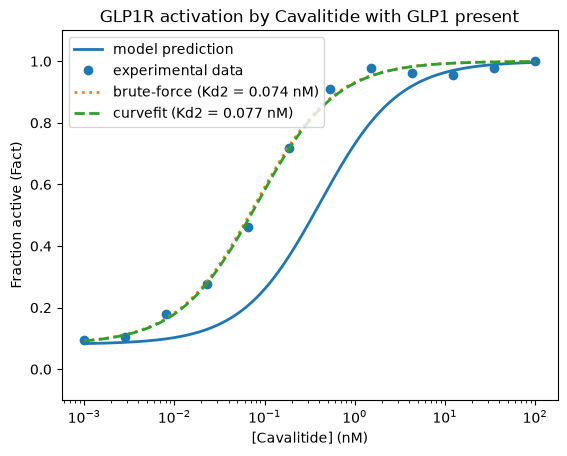

In [2]:
import matplotlib.pyplot as plt

plt.figure()
line, = plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2), lw=2, # plot baseline model prediction curve
                    label="model prediction")
plt.semilogx(L2_loaded, Fact_loaded, "o", c=line.get_color(), # overlay the experimental data points
            label="experimental data")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_brute), ":", lw=2, # plot brute-force fit curve
            label=f"brute-force (Kd2 = {Kd2_brute:.3f} nM)")
plt.semilogx(L2, Fact(L1, L2, Kd1, Kd2_fit), "--", lw=2, # plot steepest descent fit curve
            label=f"curvefit (Kd2 = {Kd2_fit:.3f} nM)")

plt.ylim(-0.1, 1.1)
plt.xlabel("[Cavalitide] (nM)")
plt.ylabel("Fraction active (Fact)")
plt.title("GLP1R activation by Cavalitide with GLP1 present")
plt.legend(loc="upper left")
plt.show()

### Fitted value of $K_d$ for Cavalitide & Interpretation 

Brute Force Dissociaton constant for Cavalitide: $K_d = 0.074$ nM <br>
Steepest Descent Dissociation constant for Cavalitide: $K_d = 0.077$ nM <br>
Dissociation constant for GLP1: $K_d = 0.17$ nM <br>
Dissociation constant for semaglutide: $K_d = 0.38$ nM <br>

The dissociation constant for Cavalitide is much lower than the dissociation constants for GLP1 and semaglutide. This indicates a stronger binding affinity, meaning that less drug is required to occupy half of the GLP1 receptors and Cavalitide binds tighter to GLP1R than both GLP1 and semaglutide. This means it is a much stronger agonist at low concentrations. Some advantages of this low $K_d$ value include a lesser dose needed, meaning there will also be less adverse side effects. The tighter binding also means that the drug can stay attached for longer, meaning one dose can last longer. However, this also means that it's easier to put too much into the body, which can cause stronger side effects. Additionally, if a patient reacts poorly to the drug, it can be harder to clear out.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

### Modeling Ozempic and Wegovy with SciPy
To simulate the pharmokinetics for the existing market leaders, we need sufficient background information about the drug's behavior in regards to it's concentration, including absorption rate and time between doses.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product: 'Ozempic' or 'Wegovy' =====
#drug = 'Ozempic'
drug = 'Wegovy'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

Euler's method could be used to graph the behavior of the models, but SciPy's solve_ivp's method is more accurate and can better account for changes in the model over time. Because of that, we modeled the behavior of the drugs using scipy_integrate_solve_ivp to solve our ordinary differential equations.

In [6]:
# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))      # Euler steps per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        y_seg = np.zeros((2, n_steps + 1))
        y_seg[:, 0] = y
        
        # Integration using Euler's method
        #for n in range(n_steps):
        #    y_seg[:, n + 1] = y_seg[:, n] + dt * np.array(ODEfunc(t_seg[n], y_seg[:, n]))

        # Integration using scipy
        solution = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y,
                     t_eval=t_seg)
        y_seg = solution.y
           
        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

Finally, by plotting our models, we can see the concentration of each drug over time.

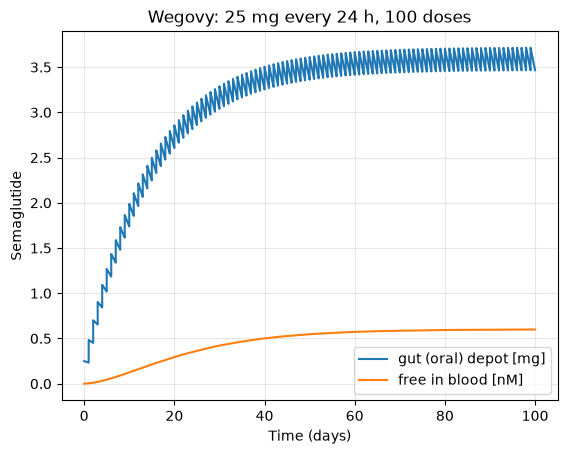

In [7]:
# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Semaglutide")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Modeling Cavalitide
Using the same model to graph our GLP-1 analog, Cavalitide, only requires a few minor changes. Although we only know it has ka = 0.006 1/h, we know that it's a daily pill, so we can assume other required information, such as bioavailability and time between doses is consistant with Wegovy, which also has an oral delivery method, allowed us to determine:
```python
    'Cavalitide': dict(Favailable=0.01,
                       ka=0.0006,
                       D=25,
                       interval=24,
                       n_doses=100,
                       depot='gut (oral)'),
```
Adding this to our model and graphing it results in:

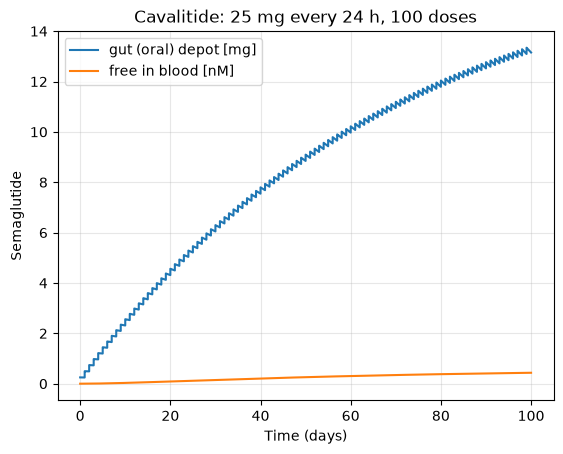

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# ===== choose product: 'Ozempic' or 'Wegovy' or 'Cavalitide' =====
#drug = 'Ozempic'
#drug = 'Wegovy'
drug = 'Cavalitide'

# product-specific parameters
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,               # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
    'Cavalitide': dict(Favailable=0.01,
                       ka=0.0006,
                       D=25,
                       interval=24,
                       n_doses=100,
                       depot='gut (oral)'),
}
p = products[drug]
Favailable, ka, D = p['Favailable'], p['ka'], p['D']
interval, n_doses, depot = p['interval'], p['n_doses'], p['depot']

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin

# simulation parameters
dt = 0.1        # h, Euler step size

def ODEfunc(t, y):
    Asc, Cc = y
    dAsc = -ka*Asc            # Asc: depot amount (mg)
    dCc = ka*Asc/V - ke*Cc    # Cc: blood concentration (mg/L)
    return [dAsc, dCc]

def simulate(D, n_doses, interval, dt):
    """Repeated dosing every `interval` h; returns time (h), depot amount (mg),
    and blood concentration (nmol/L)."""
    t_out, Asc_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))      # Euler steps per dosing interval
    for i in range(n_doses):
        y[0] += Favailable*D                 # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        y_seg = np.zeros((2, n_steps + 1))
        y_seg[:, 0] = y
        
        # explicit Euler: y[n+1] = y[n] + dt * f(t[n], y[n])
        #for n in range(n_steps):
        #    y_seg[:, n + 1] = y_seg[:, n] + dt * np.array(ODEfunc(t_seg[n], y_seg[:, n]))

        # integrate using solve_ivp
        solution = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y,
                     t_eval=t_seg)
        y_seg = solution.y
           
        t_out.append(t_seg)
        Asc_out.append(y_seg[0])
        Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()         # carry state into next interval
    t = np.concatenate(t_out)
    Asc_out = np.concatenate(Asc_out)
    Cc_out = np.concatenate(Cc_out)
    Cc_nM = Cc_out * 1e-3 / MW * 1e9
    return t, Asc_out, Cc_nM

# --- run ---
t, Asc, Cc = simulate(D, n_doses, interval, dt)

# --- plot ---
plt.plot(t / 24, Asc, label=f"{depot} depot [mg]")
plt.plot(t / 24, Ffree*Cc, label="free in blood [nM]")
plt.xlabel("Time (days)")
plt.ylabel("Semaglutide")
plt.title(f"{drug}: {D} mg every {interval} h, {n_doses} doses")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Dosing Optimization

Decreasing the daily dose from 25 mg to 20.8 mg while leaving all other factors constant results in a steady-state blood concentration level of 0.5 nM. We chose to change only this value because dose amount is the realistically the most straightforward factor to change, as we can't change the dissociation constant, and changing dose interval would make our pill inconvenient for patients. The previous dose, 25 mg, had a steady-state concentration of roughly 0.60 nM, so only a small decrease in amount was required to achieve the target concentration level.

Average concentration over final 24 h: 0.500 nM


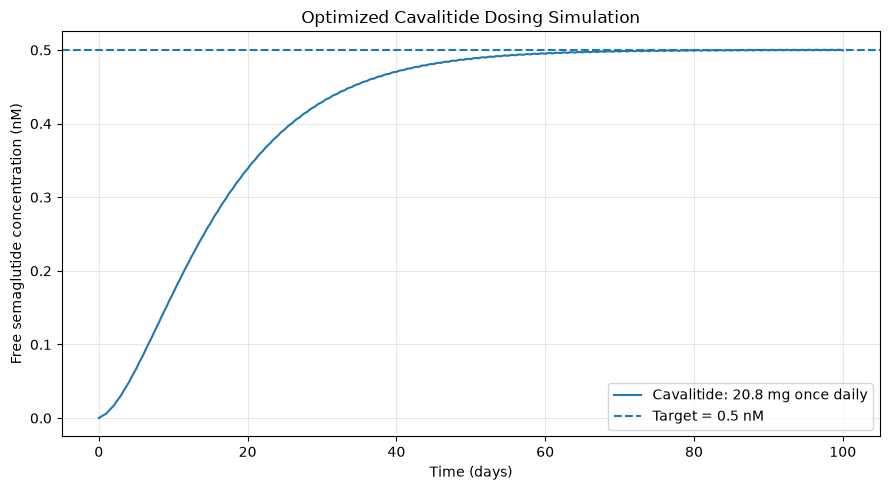

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Cavalitide parameters
Favailable = 0.01
ka = 0.006          # 1/h
D = 20.8            # mg per dose
interval = 24       # h (once daily)
n_doses = 100

# Shared model parameters
ke = 0.0039         # 1/h
V = 10.8            # L
MW = 4113.6         # g/mol
Ffree = 0.01

def ODEfunc(t, y):
    Asc, Cc = y
    return [-ka * Asc, ka * Asc / V - ke * Cc]

def simulate(D, n_doses, interval, dt=0.1):
    t_out, Cc_out = [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))
    for i in range(n_doses):
        y[0] += Favailable * D
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        solution = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y,
                             t_eval=t_seg, method="RK45",
                             rtol=1e-8, atol=1e-10)
        if not solution.success:
            raise RuntimeError(solution.message)
        t_out.append(solution.t)
        Cc_out.append(solution.y[1])
        y = solution.y[:, -1].copy()
    t = np.concatenate(t_out)
    Cc = np.concatenate(Cc_out)
    free_Cc_nM = Ffree * Cc * 1e6 / MW
    return t / 24, free_Cc_nM

time_days, free_concentration = simulate(D, n_doses, interval)
final_interval = time_days >= (n_doses - 1) * interval / 24
steady_state_average = np.mean(free_concentration[final_interval])
print(f"Average concentration over final 24 h: {steady_state_average:.3f} nM")

plt.figure(figsize=(9, 5))
plt.plot(time_days, free_concentration, label=f"Cavalitide: {D:.1f} mg once daily")
plt.axhline(0.5, linestyle="--", label="Target = 0.5 nM")
plt.xlabel("Time (days)")
plt.ylabel("Free semaglutide concentration (nM)")
plt.title("Optimized Cavalitide Dosing Simulation")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("Cavalitide_optimized_dosing.png", dpi=300, bbox_inches="tight")
plt.show()

## Task 3: Simulate a combined pharmacokinetics-pharmacokinetics (PKPD) model that predicts GLP1 receptor activity during treatment

### GLP1R Receptor Activation

Using the optimized Cavalitide dose from Task 2 and the optimized dissociation constant from Task 1, we can model the total fraction of active GLP1R receptors over 100 days of treatment.

Optimized Cavalitide Kd2: 0.077 nM
Mean GLP1R activation on day 100: 0.8681
Day 100 activation range: 0.8680–0.8682


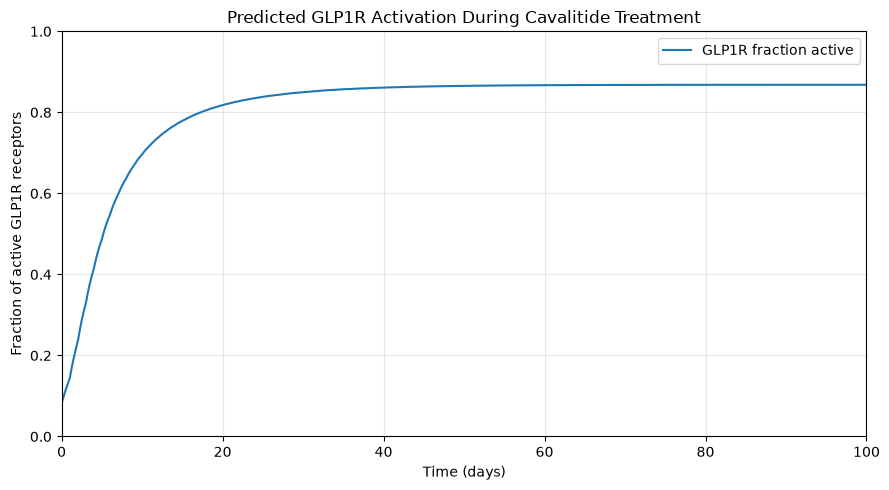

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Cavalitide pharmacokinetic parameters (from Task 2)
Favailable = 0.01
ka = 0.006          # 1/h
D = 20.8            # mg per daily dose, optimized in Task 2
interval = 24       # h
n_doses = 100       # 100 days

# Shared PK parameters
ke = 0.0039         # 1/h
V = 10.8            # L
MW = 4113.6         # g/mol
Ffree = 0.01        # fraction unbound in blood

# GLP1 receptor pharmacodynamic parameters (from Task 1)
Kd1 = 0.17          # nM, GLP-1 dissociation constant
Kd2 = 0.077         # nM, optimized Cavalitide dissociation constant
L1 = 0.015          # nM, fasting GLP-1 concentration

def ODEfunc(t, y):
    """PK model: depot amount (mg) and blood concentration (mg/L)."""
    Asc, Cc = y
    return [-ka * Asc, ka * Asc / V - ke * Cc]

def Fact(L1, L2, Kd1, Kd2):
    """Fraction of GLP1R receptors activated by GLP-1 and Cavalitide."""
    return (Kd2 * L1 + Kd1 * L2) / (
        Kd1 * Kd2 + Kd2 * L1 + Kd1 * L2
    )

def simulate_pkpd():
    y = np.array([0.0, 0.0])
    t_out, active_out = [], []
    dt = 0.1

    for i in range(n_doses):
        y[0] += Favailable * D
        t0, t1 = i * interval, (i + 1) * interval
        t_eval = t0 + dt * np.arange(int(round(interval / dt)) + 1)

        solution = solve_ivp(
            ODEfunc, (t0, t1), y, t_eval=t_eval,
            method="RK45", rtol=1e-8, atol=1e-10
        )
        if not solution.success:
            raise RuntimeError(solution.message)

        start = 0 if i == 0 else 1
        t_out.append(solution.t[start:])
        total_nM = solution.y[1, start:] * 1e6 / MW
        free_nM = Ffree * total_nM
        active_out.append(Fact(L1, free_nM, Kd1, Kd2))
        y = solution.y[:, -1].copy()

    return np.concatenate(t_out) / 24, np.concatenate(active_out)

if __name__ == "__main__":
    time_days, fraction_active = simulate_pkpd()
    final_day = time_days >= 99
    print(f"Optimized Cavalitide Kd2: {Kd2:.3f} nM")
    print(f"Mean GLP1R activation on day 100: "
          f"{np.mean(fraction_active[final_day]):.4f}")
    print(f"Day 100 activation range: "
          f"{np.min(fraction_active[final_day]):.4f}–"
          f"{np.max(fraction_active[final_day]):.4f}")

    plt.figure(figsize=(9, 5))
    plt.plot(time_days, fraction_active, label="GLP1R fraction active")
    plt.xlabel("Time (days)")
    plt.ylabel("Fraction of active GLP1R receptors")
    plt.title("Predicted GLP1R Activation During Cavalitide Treatment")
    plt.xlim(0, 100)
    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig("cavalitidePKPD_receptor_activation.png",
                dpi=300, bbox_inches="tight")
    plt.show()

The model shows that receptor activation increases sharply until it reaches a steady state at around 86.8% activation.

### Optimization of Receptor Activation

By increasing the daily dose from 20.8 to 28.5, we achieve 90% receptor activation at steady state. We chose to adjust only dose amount for the same reason as in Task 2, because it's the most sensible change. By increasing the dose, we can increase the fraction of activated receptors. Clinically, by increasing receptor activation, we can increase the drug's efficacy, helping patients see more positive change in less time.

Mean GLP1R activation on day 100: 0.8999
Day 100 activation range: 0.8998–0.8999


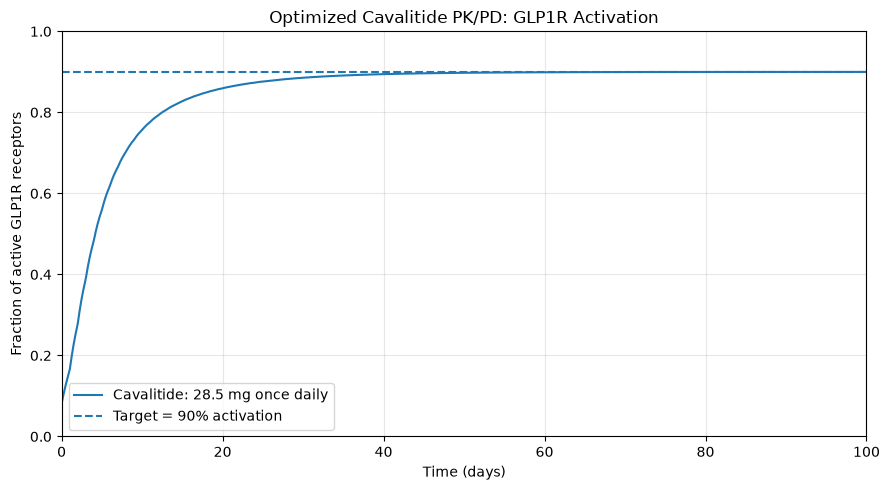

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Cavalitide pharmacokinetic parameters
Favailable = 0.01
ka = 0.006          # 1/h
D = 28.5            # mg per daily dose (increased from 20.8 mg)
interval = 24       # h between doses
n_doses = 100

# Shared PK parameters
ke = 0.0039         # 1/h
V = 10.8            # L
MW = 4113.6         # g/mol
Ffree = 0.01

# GLP1 receptor pharmacodynamic parameters
Kd1 = 0.17          # nM
Kd2 = 0.077         # nM, optimized Cavalitide Kd
L1 = 0.015          # nM, fasting GLP-1

def ODEfunc(t, y):
    Asc, Cc = y
    return [-ka * Asc, ka * Asc / V - ke * Cc]

def Fact(L1, L2, Kd1, Kd2):
    return (Kd2 * L1 + Kd1 * L2) / (
        Kd1 * Kd2 + Kd2 * L1 + Kd1 * L2
    )

def simulate_pkpd():
    y = np.array([0.0, 0.0])
    t_out, active_out = [], []
    dt = 0.1
    for i in range(n_doses):
        y[0] += Favailable * D
        t0, t1 = i * interval, (i + 1) * interval
        t_eval = t0 + dt * np.arange(int(round(interval / dt)) + 1)
        solution = solve_ivp(
            ODEfunc, (t0, t1), y, t_eval=t_eval,
            method="RK45", rtol=1e-8, atol=1e-10
        )
        if not solution.success:
            raise RuntimeError(solution.message)
        start = 0 if i == 0 else 1
        free_nM = Ffree * solution.y[1, start:] * 1e6 / MW
        t_out.append(solution.t[start:])
        active_out.append(Fact(L1, free_nM, Kd1, Kd2))
        y = solution.y[:, -1].copy()
    return np.concatenate(t_out) / 24, np.concatenate(active_out)

if __name__ == "__main__":
    time_days, fraction_active = simulate_pkpd()
    final_day = time_days >= 99
    print(f"Mean GLP1R activation on day 100: {np.mean(fraction_active[final_day]):.4f}")
    print(f"Day 100 activation range: {np.min(fraction_active[final_day]):.4f}–{np.max(fraction_active[final_day]):.4f}")

    plt.figure(figsize=(9, 5))
    plt.plot(time_days, fraction_active, label=f"Cavalitide: {D} mg once daily")
    plt.axhline(0.90, linestyle="--", label="Target = 90% activation")
    plt.xlabel("Time (days)")
    plt.ylabel("Fraction of active GLP1R receptors")
    plt.title("Optimized Cavalitide PK/PD: GLP1R Activation")
    plt.xlim(0, 100)
    plt.ylim(0, 1)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig("cavalitidePKPD_90percent.png", dpi=300, bbox_inches="tight")
    plt.show()

## Conclusions:

When comparing Cavalitide to the similarly administered Wegovy, after 100 days of 25 mg Cavalitide, there is an amount of ~13 mg of the drug in the gut. Conversely, the same amount of Wegovy after the same amount of time only has an amount of ~3.5 mg gut, showing how much more effective Cavalitide is. In addition, 8 doses of 2.5 mg of Ozempic has a peak concentration of a little over 1.75 mg in the gut, significantly less than both.

## Limitations and Future Work:

Describe the limitations of your project. If you had more time or additional data, explain how you would improve the analysis.

## AI Usage Statement:
*This is where you will provide a short description on whether AI (and which AI) was used for any of the sections above and whether it helped or why it did not help.*
- *Example statement: "We used Claude Code to generate our linear regression plot. At first, it did not include an R^2 calculation, so we added it to the code afterwards."*

## GitHub Repository Link:
https://github.com/amccollbrady/bme2315_module3_pharmacology

## References:
1. https://www.mayoclinic.org/diseases-conditions/obesity/symptoms-causes/syc-20375742
2. https://my.clevelandclinic.org/health/treatments/13901-glp-1-agonists
3. https://consultqd.clevelandclinic.org/a-new-tool-in-the-obesity-management-toolbox
4. https://pmc.ncbi.nlm.nih.gov/articles/PMC13675972/#s0006

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*